# La classe Conv2d en PyTorch
### Par Mohamed Bowba


In [1]:
# import des librairies
import numpy as np
import torch
import torch.nn as nn

import matplotlib.pyplot as plt


# Créer une instance de convolution

In [2]:
# créer une instance de nn.Conv2d avec ses paramètres

# paramètres
inChans  = 3   # RGB
outChans = 15
krnSize  = 5   # doit être un nombre impair
stride   = 1
padding  = 0

# création de l'instance (cf. nn.Linear)
c = nn.Conv2d(inChans, outChans, krnSize, stride, padding)

# affichage de l'objet
print(c)
print(' ')

# on regarde le tenseur de poids (weight) ; quelles sont ses dimensions ?
print('Taille des poids (weight) : ' + str(c.weight.shape))
print('Taille du biais (bias)   : ' + str(c.bias.shape))


Conv2d(3, 15, kernel_size=(5, 5), stride=(1, 1))
 
Taille des poids (weight) : torch.Size([15, 3, 5, 5])
Taille du biais (bias)   : torch.Size([15])


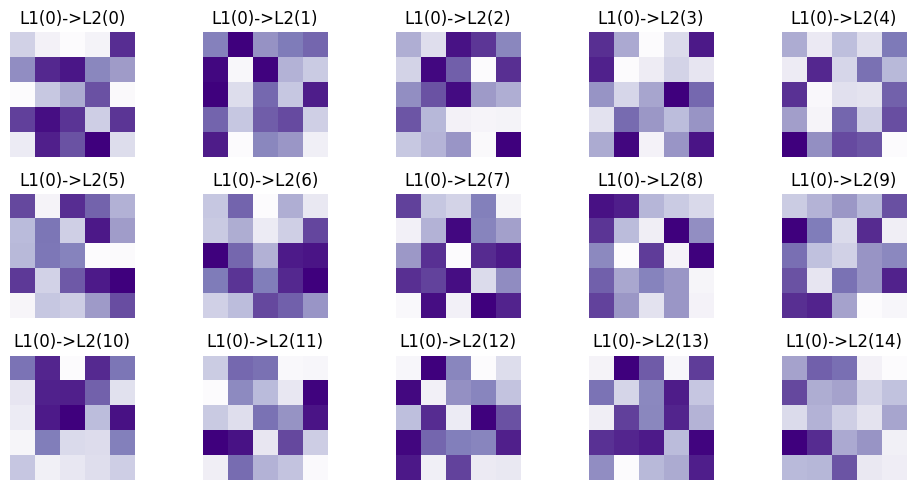

In [3]:
# À quoi ressemblent ces filtres (kernels) ?

fig, axs = plt.subplots(3, 5, figsize=(10, 5))

for i, ax in enumerate(axs.flatten()):
  ax.imshow(torch.squeeze(c.weight[i, 0, :, :]).detach(), cmap='Purples')
  ax.set_title('L1(0)->L2(%s)' % i)
  ax.axis('off')

plt.tight_layout()
plt.show()


# Convoluer avec une image

torch.Size([1, 3, 64, 64])
(64, 64, 3, 1)


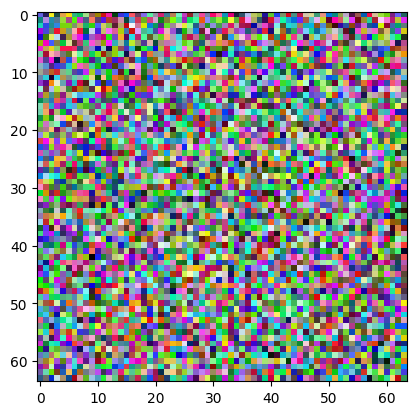

In [4]:
# taille de l'image (N, RGB, hauteur, largeur)
imsize = (1, 3, 64, 64)

img = torch.rand(imsize)

# pytorch veut les canaux en premier, mais matplotlib veut les canaux en dernier.
# il faut donc permuter le tenseur pour pouvoir le visualiser
img2view = img.permute(2, 3, 1, 0).numpy()
print(img.shape)
print(img2view.shape)

plt.imshow(np.squeeze(img2view));


In [5]:
# on convolue l'image avec la banque de filtres (l'ensemble des 'outChans' kernels)
convRes = c(img)

print(img.shape)
print(convRes.shape)


torch.Size([1, 3, 64, 64])
torch.Size([1, 15, 60, 60])


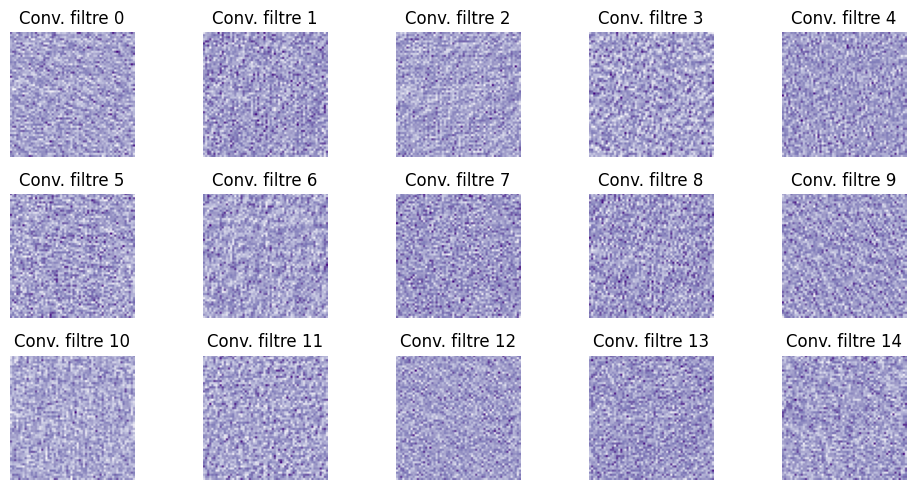

In [6]:
# à quoi ressemblent les images convoluées ?

fig, axs = plt.subplots(3, 5, figsize=(10, 5))

for i, ax in enumerate(axs.flatten()):

  # on extrait cette "couche" du résultat de la convolution
  I = torch.squeeze(convRes[0, i, :, :]).detach()

  # et on la visualise
  ax.imshow(I, cmap='Purples')
  ax.set_title('Conv. filtre %s' % i)
  ax.axis('off')

plt.tight_layout()
plt.show()


# Explorations personnelles — Mohamed Bowba

In [7]:
# 1) Faire varier padding et stride pendant quelques minutes, et observer comment cela
#    change la taille du résultat de la convolution (variable convRes).
#
# 2) Vérifier : la taille de sortie suit la formule
#    out = floor((in + 2*padding - kernel) / stride) + 1
#    Essayer de retrouver cette formule à la main avec les valeurs ci-dessus.
